In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("MetroPT3(AirCompressor).csv")

In [11]:
df.head()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [12]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1516948, 17)


In [13]:
df.tail()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
1516943,15169430,2020-09-01 03:59:10,-0.014,8.918,8.906,-0.022,8.918,59.675,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1516944,15169440,2020-09-01 03:59:20,-0.014,8.904,8.888,-0.020,8.904,59.600,0.0450,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1516945,15169450,2020-09-01 03:59:30,-0.014,8.890,8.876,-0.022,8.892,59.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1516946,15169460,2020-09-01 03:59:40,-0.012,8.876,8.864,-0.022,8.878,59.550,0.0450,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1516947,15169470,2020-09-01 03:59:50,-0.014,8.860,8.848,-0.022,8.864,59.475,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [14]:
df.columns.tolist()

['Unnamed: 0',
 'timestamp',
 'TP2',
 'TP3',
 'H1',
 'DV_pressure',
 'Reservoirs',
 'Oil_temperature',
 'Motor_current',
 'COMP',
 'DV_eletric',
 'Towers',
 'MPG',
 'LPS',
 'Pressure_switch',
 'Oil_level',
 'Caudal_impulses']

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  str    
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-null  float64
 15  Oil_level        1516948 non-null  float64
 16  Caudal_impulses  1516948 non-

In [16]:
df['Unnamed: 0'].head(10)

0     0
1    10
2    20
3    30
4    40
5    50
6    60
7    70
8    80
9    90
Name: Unnamed: 0, dtype: int64

In [17]:
print("First value:", df['Unnamed: 0'].iloc[0])
print("Last value:", df['Unnamed: 0'].iloc[-1])


print("Unique differences:", df['Unnamed: 0'].diff().dropna().unique()[:10])

First value: 0
Last value: 15169470
Unique differences: [10.]


The Unnamed: 0 column contains sequential values starting from 0, increasing by 10 in each row. 
It does not appear to represent a sensor measurementز

In [18]:
df.describe()

,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06
mean,7.584735e+06,1.367826e+00,8.984611e+00,7.568155e+00,5.595619e-02,8.985233e+00,6.264418e+01,2.050171e+00,8.369568e-01,1.606106e-01,9.198483e-01,8.326640e-01,3.420025e-03,9.914368e-01,9.041556e-01,9.371066e-01
std,4.379053e+06,3.250930e+00,6.390951e-01,3.333200e+00,3.824015e-01,6.383070e-01,6.516261e+00,2.302053e+00,3.694052e-01,3.671716e-01,2.715280e-01,3.732757e-01,5.838091e-02,9.214078e-02,2.943779e-01,2.427712e-01
min,0.000000e+00,-3.200000e-02,7.300000e-01,-3.600000e-02,-3.200000e-02,7.120000e-01,1.540000e+01,2.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.792368e+06,-1.400000e-02,8.492000e+00,8.254000e+00,-2.200000e-02,8.494000e+00,5.777500e+01,4.000000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
50%,7.584735e+06,-1.200000e-02,8.960000e+00,8.784000e+00,-2.000000e-02,8.960000e+00,6.270000e+01,4.500000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.137710e+07,-1.000000e-02,9.492000e+00,9.374000e+00,-1.800000e-02,9.492000e+00,6.725000e+01,3.807500e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.516947e+07,1.067600e+01,1.030200e+01,1.028800e+01,9.844000e+00,1.030000e+01,8.905000e+01,9.295000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


1. All numerical columns contain 1,516,948 values.

2. لحد دلوقتى مفيش missing values.

3. Sensor measurements have different ranges and scales.

4. Some columns contain values between 0 and 1.

5. Negative minimum values were observed in TP2, H1, and DV_pressure.

6. Oil_temperature ranges from 15.4 to 89.05.

Checking Unique Values

In [19]:
binary_columns = [
    'COMP', 'DV_eletric', 'Towers', 'MPG',
    'LPS', 'Pressure_switch', 'Oil_level',
    'Caudal_impulses'
]


for col in binary_columns:
    print(f"{col}: {df[col].unique()}")

COMP: [1. 0.]
DV_eletric: [0. 1.]
Towers: [1. 0.]
MPG: [1. 0.]
LPS: [0. 1.]
Pressure_switch: [1. 0.]
Oil_level: [1. 0.]
Caudal_impulses: [1. 0.]


1. All eight inspected columns contain only two unique values: 0 and 1.

2. These columns can be classified as binary features

In [ ]:
# Checking Duplicate Records

df.duplicated().sum()

# مفيش صفوف مكررة في الداتا

np.int64(0)

In [ ]:
# Convert timestamp column to datetime

df['timestamp'] = pd.to_datetime(df['timestamp'])

df['timestamp'].dtype

dtype('<M8[us]')

In [24]:
# Check the earliest and latest timestamps

print("Start Date:", df['timestamp'].min())
print("End Date:", df['timestamp'].max())

print("Is Chronologically Sorted:", df['timestamp'].is_monotonic_increasing)

# مش هعمل sorting للداتا علشان هى اصلا مترتبه

Start Date: 2020-02-01 00:00:00
End Date: 2020-09-01 03:59:50
Is Chronologically Sorted: True


In [25]:
# Check for duplicate timestamps

timestamp_duplicates = df['timestamp'].duplicated().sum()

print("Number of Duplicate Timestamps:", timestamp_duplicates)

Number of Duplicate Timestamps: 0


1. The dataset from February 1, 2020, to September 1, 2020.

2. The records are already sorted.

3. No duplicate timestamps were found.

In [26]:
# Calculate the time difference between consecutive records

time_diff = df['timestamp'].diff()


print(time_diff.value_counts().head(10))

timestamp
0 days 00:00:10    1337521
0 days 00:00:09     128277
0 days 00:00:12      38321
0 days 00:00:13       7988
0 days 00:00:11       4471
0 days 00:00:21         10
0 days 00:00:19          5
0 days 00:00:22          4
0 days 00:00:20          3
0 days 00:00:17          3
Name: count, dtype: int64


الفاصل الزمنى بين معظم السجلات هى 10 ثوانى بس فى فواصل زمنيه اقل واكتر من 10 ثوانى وده يدل ان الداتا مش منظمه

In [28]:
# Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

Unnamed: 0         0
timestamp          0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64


In [29]:
# Calculate the percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Unnamed: 0         0.0
timestamp          0.0
TP2                0.0
TP3                0.0
H1                 0.0
DV_pressure        0.0
Reservoirs         0.0
Oil_temperature    0.0
Motor_current      0.0
COMP               0.0
DV_eletric         0.0
Towers             0.0
MPG                0.0
LPS                0.0
Pressure_switch    0.0
Oil_level          0.0
Caudal_impulses    0.0
dtype: float64


In [30]:

df.describe().loc[['min', 'max']].T

,min,max
Unnamed: 0,0.0,15169470.0
timestamp,2020-02-01 00:00:00,2020-09-01 03:59:50
TP2,-0.032,10.676
TP3,0.73,10.302
H1,-0.036,10.288
DV_pressure,-0.032,9.844
Reservoirs,0.712,10.3
Oil_temperature,15.4,89.05
Motor_current,0.02,9.295
COMP,0.0,1.0


In [32]:
# check binary columns

binary_columns = [
    'COMP', 'DV_eletric', 'Towers', 'MPG',
    'LPS', 'Pressure_switch', 'Oil_level',
    'Caudal_impulses'
]

for col in binary_columns:
    invalid_values = df.loc[~df[col].isin([0, 1]), col].unique()
    print(f"{col}: {invalid_values}")

#  كل binary columns تحتوى على 0 و 1 

COMP: []
DV_eletric: []
Towers: []
MPG: []
LPS: []
Pressure_switch: []
Oil_level: []
Caudal_impulses: []


In [33]:
sensor_columns = [
    'TP2', 'TP3', 'H1', 'DV_pressure',
    'Reservoirs', 'Oil_temperature', 'Motor_current'
]


for col in sensor_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    print(f"{col}: {outliers_count}")

TP2: 269592
TP3: 4518
H1: 241327
DV_pressure: 113111
Reservoirs: 4526
Oil_temperature: 5194
Motor_current: 0


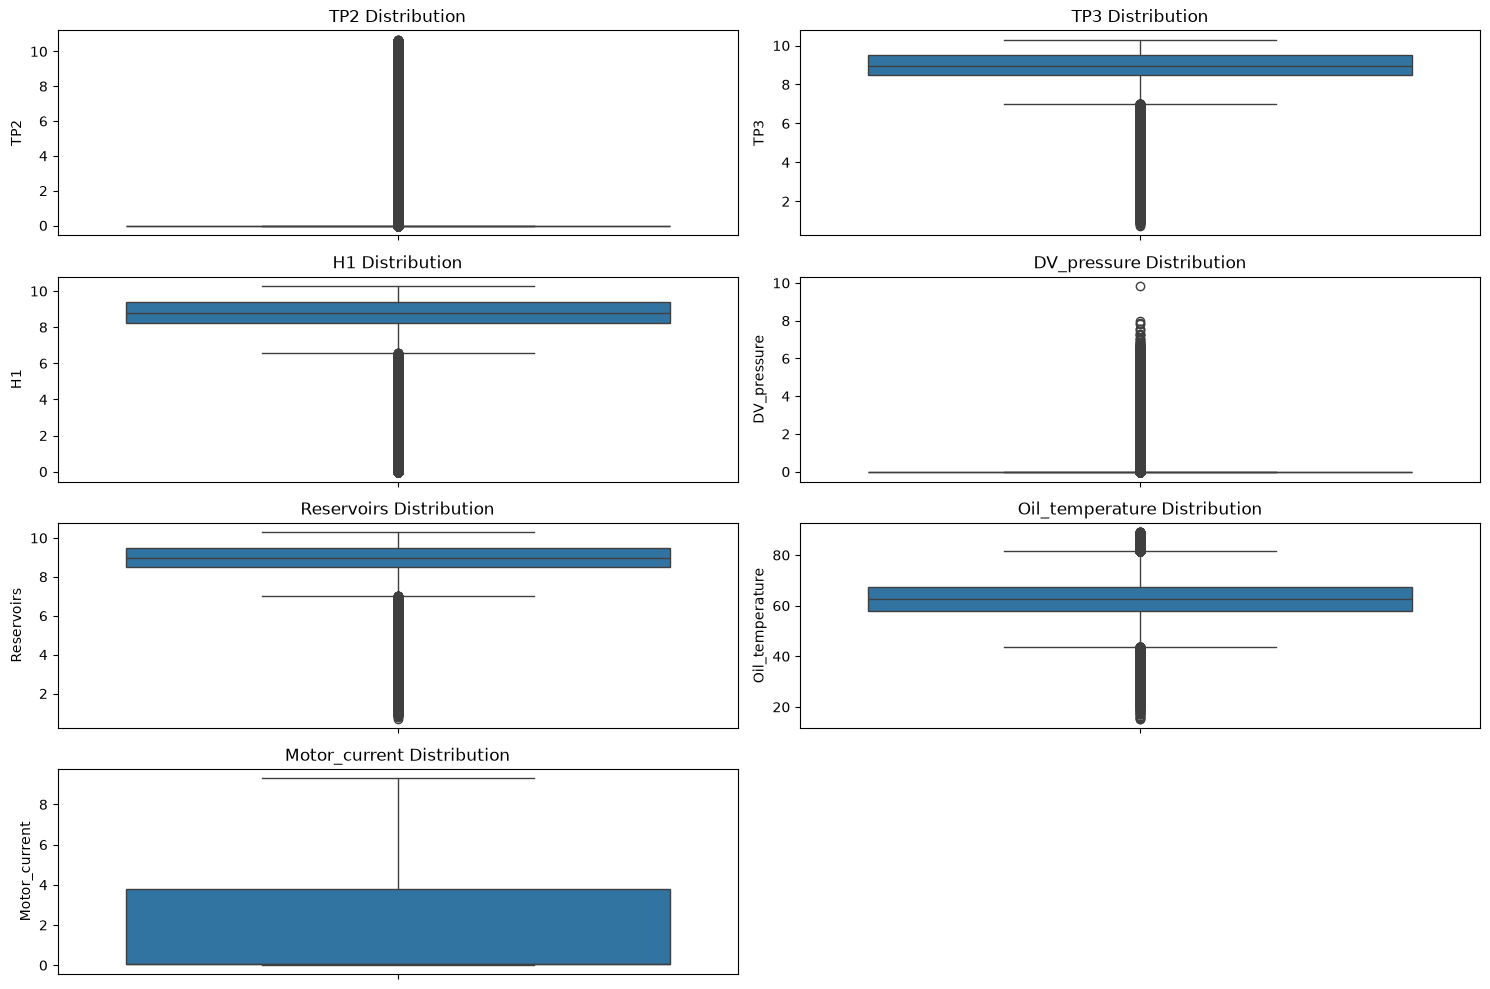

In [34]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(sensor_columns, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'{col} Distribution')

plt.tight_layout()
plt.show()

notes:

TP2: التوزيع شديد الانحراف مع عدد كبير من القيم الشاذة المحتملة

H1 and DV_pressure : يحتوى على عدد كبير من القيم الشاذه.

TP3, Reservoirs, and Oil_temperature: أعداد أقل من القيم الشاذة.

Motor_current: مفهوش قيم شاذه.

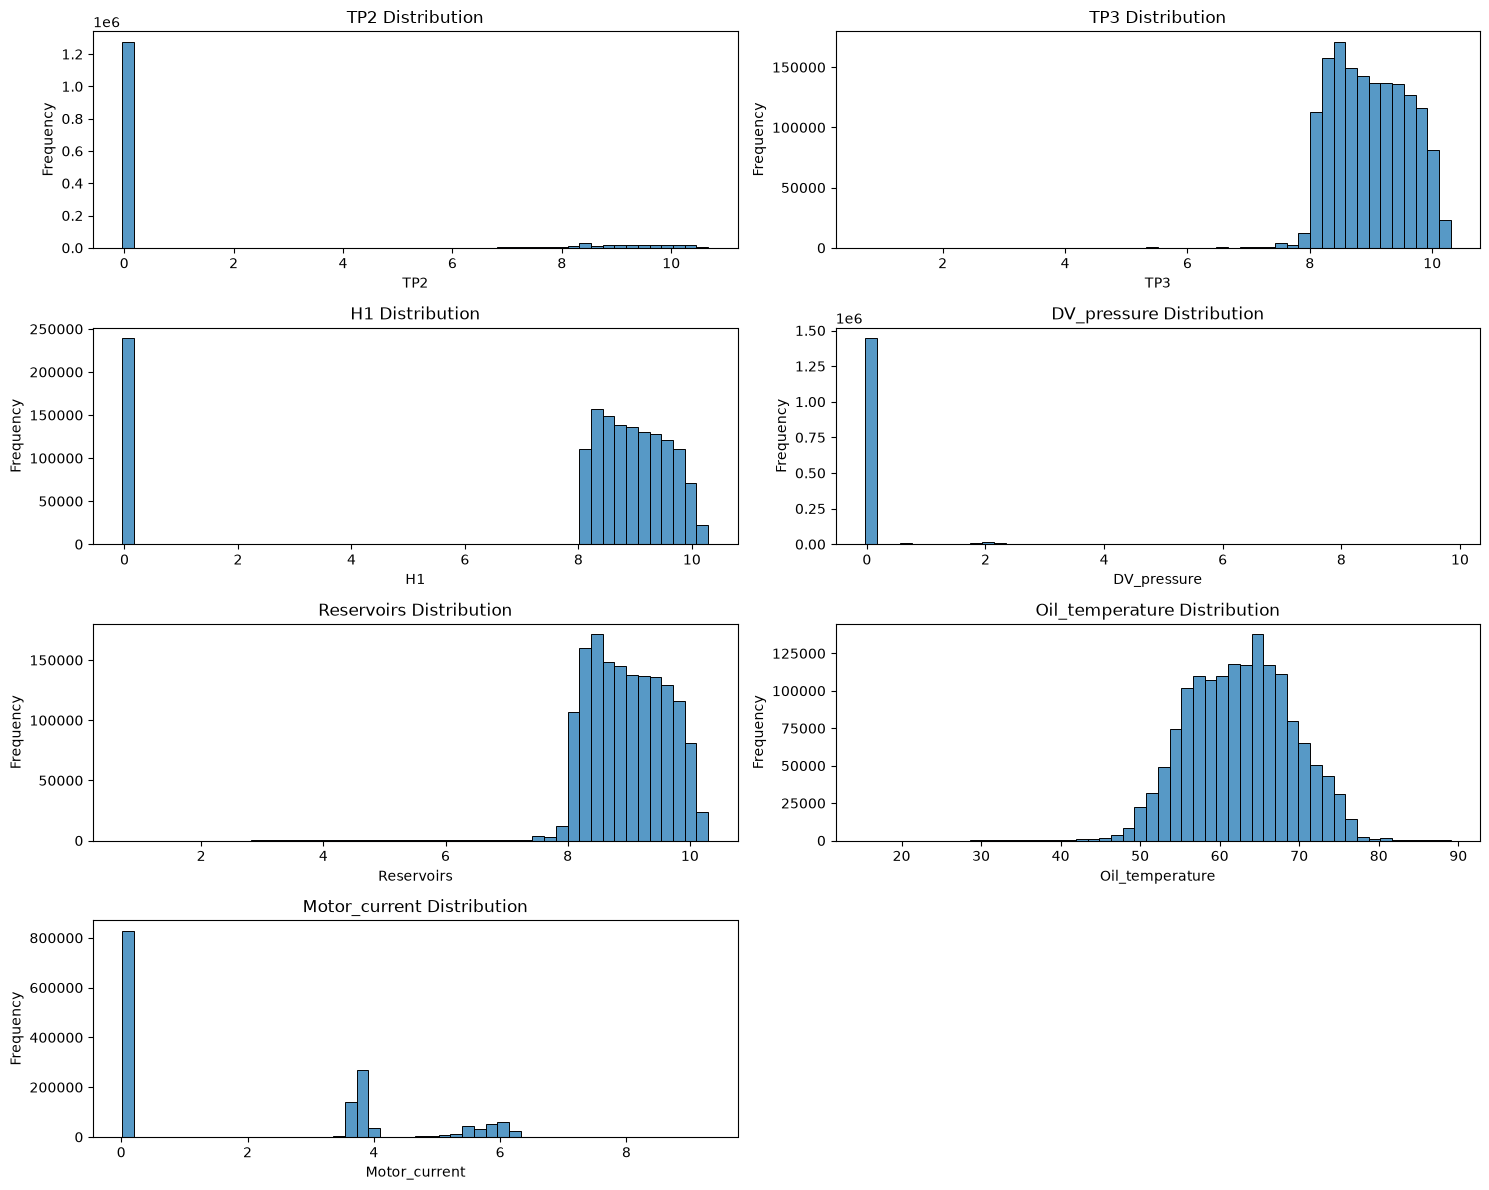

In [35]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(sensor_columns, 1):
    plt.subplot(4, 2, i)
    sns.histplot(data=df, x=col, bins=50)
    plt.title(f'{col} Distribution')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

TP2, H1, and DV_pressure: فيهم عدد كبير من القيم قريبه من الصفر بينما باقى القيم بتتوزع على نطاقات اوسع.

TP3 and Reservoirs: متشابهين فى التوزيع, ومعظمها بين 8و10

Oil_temperature: معظمها بين 60و68

Motor_current:فيه عدد قيم مختلفه وده بيدل على اختلاف حالات التشغيل

In [36]:
print(np.isinf(df.select_dtypes(include=np.number)).sum())

Unnamed: 0         0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64


In [37]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [39]:
print(df.columns.tolist())
print("Dataset Shape:", df.shape)

# هنا حذفت العمود الإضافي غير الضروري 'Unnamed: 0' لأنه لا يحتوي على معلومات مفيدة للتحليل.
# كده بقينا 16 columns بدل 17

['timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
Dataset Shape: (1516948, 16)


In [40]:
# عدد القيم السالبة في TP2, H1, DV_pressure

for col in sensor_columns:
    negative_count = (df[col] < 0).sum()
    print(f"{col}: {negative_count}")

TP2: 1275474
TP3: 0
H1: 237996
DV_pressure: 1444001
Reservoirs: 0
Oil_temperature: 0
Motor_current: 0


In [41]:
# تحليل القيم السالبة 

for col in sensor_columns:
    negative_values = df.loc[df[col] < 0, col]

    if not negative_values.empty:
        print(f"\n{col}")
        print("Minimum:", negative_values.min())
        print("Maximum:", negative_values.max())
        print("Mean:", negative_values.mean())


TP2
Minimum: -0.032
Maximum: -0.0019999999999988
Mean: -0.01279031011216159

H1
Minimum: -0.0360000000000013
Maximum: -0.0019999999999988
Mean: -0.012785021597001046

DV_pressure
Minimum: -0.032
Maximum: -0.0019999999999988
Mean: -0.020108742306964678


In [42]:
for col in binary_columns:
    print(f"\n{col}")
    print(df[col].value_counts())
    print("-" * 25)


COMP
COMP
1.0    1269620
0.0     247328
Name: count, dtype: int64
-------------------------

DV_eletric
DV_eletric
0.0    1273310
1.0     243638
Name: count, dtype: int64
-------------------------

Towers
Towers
1.0    1395362
0.0     121586
Name: count, dtype: int64
-------------------------

MPG
MPG
1.0    1263108
0.0     253840
Name: count, dtype: int64
-------------------------

LPS
LPS
0.0    1511760
1.0       5188
Name: count, dtype: int64
-------------------------

Pressure_switch
Pressure_switch
1.0    1503958
0.0      12990
Name: count, dtype: int64
-------------------------

Oil_level
Oil_level
1.0    1371557
0.0     145391
Name: count, dtype: int64
-------------------------

Caudal_impulses
Caudal_impulses
1.0    1421542
0.0      95406
Name: count, dtype: int64
-------------------------


In [43]:
print(df.dtypes)

timestamp          datetime64[us]
TP2                       float64
TP3                       float64
H1                        float64
DV_pressure               float64
Reservoirs                float64
Oil_temperature           float64
Motor_current             float64
COMP                      float64
DV_eletric                float64
Towers                    float64
MPG                       float64
LPS                       float64
Pressure_switch           float64
Oil_level                 float64
Caudal_impulses           float64
dtype: object


In [44]:
# Extract time-based features from timestamp

df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['day'] = df['timestamp'].dt.day
df['month'] = df['timestamp'].dt.month

In [45]:
print(df[['timestamp', 'hour', 'day_of_week', 'day', 'month']].head())

            timestamp  hour  day_of_week  day  month
0 2020-02-01 00:00:00     0            5    1      2
1 2020-02-01 00:00:10     0            5    1      2
2 2020-02-01 00:00:19     0            5    1      2
3 2020-02-01 00:00:29     0            5    1      2
4 2020-02-01 00:00:39     0            5    1      2


In [46]:
# Extract additional time-based features

df['minute'] = df['timestamp'].dt.minute
df['day_of_year'] = df['timestamp'].dt.dayofyear

In [47]:
# Calculate time differences between consecutive records

time_diff = df['timestamp'].diff().dt.total_seconds()

print("Minimum interval:", time_diff.min(), "seconds")
print("Maximum interval:", time_diff.max(), "seconds")
print("Mean interval:", time_diff.mean(), "seconds")

Minimum interval: 8.0 seconds
Maximum interval: 172918.0 seconds
Mean interval: 12.141221809331507 seconds


In [48]:
# تحليل الفجوات الزمنية بين السجلات 

print("Median interval:", time_diff.median(), "seconds")

print("\nNumber of time gaps:")
print("More than 10 seconds:", (time_diff > 10).sum())
print("More than 1 minute:", (time_diff > 60).sum())
print("More than 10 minutes:", (time_diff > 600).sum())
print("More than 1 hour:", (time_diff > 3600).sum())

Median interval: 10.0 seconds

Number of time gaps:
More than 10 seconds: 51147
More than 1 minute: 331
More than 10 minutes: 230
More than 1 hour: 160


استخدمت Median بدل Mean لان ال Mean بياثر على gaps الكبيره بينما Median هو القيمه الموجوده فى المنتصف وده يدينا فكره افضل عن الفاصل الزمنى بين القراءات

In [49]:
# Locate the largest time gap

largest_gap_index = time_diff.idxmax()

gap_start = df.loc[largest_gap_index - 1, 'timestamp']
gap_end = df.loc[largest_gap_index, 'timestamp']

print("Gap Start:", gap_start)
print("Gap End:", gap_end)
print("Gap Duration:", time_diff.loc[largest_gap_index], "seconds")

Gap Start: 2020-04-25 01:10:51
Gap End: 2020-04-27 01:12:49
Gap Duration: 172918.0 seconds


Median 10 ثوانى بينما Mean 12.14sec 

اكبر gap حصلت بين 25-4-2020 لحد 27-4-2020 واستمرت حوالى 48 ساعه

In [50]:
# Identify time gaps longer than 10 minutes

gap_threshold = 600

large_gaps = pd.DataFrame({
    'Gap Start': df['timestamp'].shift(1),
    'Gap End': df['timestamp'],
    'Duration (seconds)': time_diff
})

large_gaps = large_gaps[
    large_gaps['Duration (seconds)'] > gap_threshold
]

large_gaps = large_gaps.reset_index(drop=True)

print("Number of large gaps:", len(large_gaps))
display(large_gaps.head(10))

Number of large gaps: 230


,Gap Start,Gap End,Duration (seconds)
0,2020-02-01 19:40:04,2020-02-01 23:15:33,12929.0
1,2020-02-01 23:20:21,2020-02-02 04:34:27,18846.0
2,2020-02-05 00:32:21,2020-02-05 00:43:00,639.0
3,2020-02-05 01:07:37,2020-02-05 04:28:42,12065.0
4,2020-02-06 02:07:01,2020-02-06 07:52:21,20720.0
5,2020-02-06 14:08:53,2020-02-06 14:19:23,630.0
6,2020-02-06 19:16:35,2020-02-06 23:33:19,15404.0
7,2020-02-06 23:48:02,2020-02-07 04:28:13,16811.0
8,2020-02-09 00:49:56,2020-02-09 04:38:36,13720.0
9,2020-02-10 01:17:01,2020-02-10 04:39:03,12122.0


In [51]:
gap_duration = large_gaps['Duration (seconds)']

gap_categories = pd.cut(
    gap_duration,
    bins=[600, 3600, 21600, 86400, float('inf')],
    labels=['10 minutes - 1 hour',
            '1 - 6 hours',
            '6 - 24 hours',
            'More than 24 hours']
)

print(gap_categories.value_counts().sort_index())

Duration (seconds)
10 minutes - 1 hour     70
1 - 6 hours            128
6 - 24 hours            27
More than 24 hours       5
Name: count, dtype: int64


In [52]:
# 10 longest time gaps

display(
    large_gaps.sort_values(
        by='Duration (seconds)',
        ascending=False
    ).head(10)
)

,Gap Start,Gap End,Duration (seconds)
81,2020-04-25 01:10:51,2020-04-27 01:12:49,172918.0
160,2020-06-27 10:53:07,2020-06-28 23:07:43,130476.0
26,2020-02-28 23:57:08,2020-03-01 04:00:09,100981.0
198,2020-08-04 07:42:28,2020-08-05 08:23:01,88833.0
126,2020-05-24 00:39:23,2020-05-25 01:14:14,88491.0
168,2020-07-07 15:24:51,2020-07-08 15:20:51,86160.0
216,2020-08-22 19:11:44,2020-08-23 18:51:01,85157.0
107,2020-05-10 00:31:17,2020-05-10 22:48:58,80261.0
141,2020-06-07 14:19:39,2020-06-08 11:48:04,77305.0
52,2020-04-01 13:15:40,2020-04-02 09:59:17,74617.0


In [53]:
df['segment_id'] = (time_diff > 60).cumsum()

print("Number of time segments:", df['segment_id'].nunique())
print("\nRecords in each segment:")
print(df['segment_id'].value_counts().sort_index().head())

Number of time segments: 332

Records in each segment:
segment_id
0     4654
1     2460
2       30
3     1110
4    23550
Name: count, dtype: int64


In [54]:
segment_sizes = df.groupby('segment_id').size()

print(segment_sizes.describe())

count      332.000000
mean      4569.120482
std       5745.062243
min         29.000000
25%        150.000000
50%       2339.000000
75%       7230.000000
max      36599.000000
dtype: float64


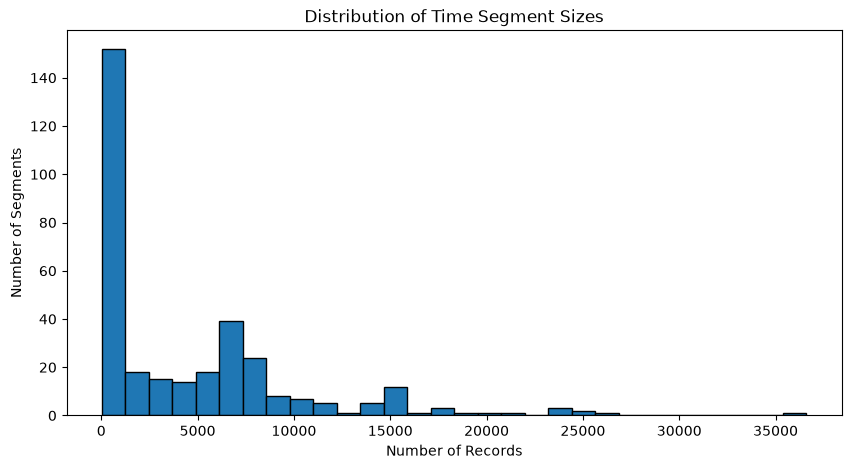

In [55]:
plt.figure(figsize=(10, 5))

plt.hist(segment_sizes, bins=30, edgecolor='black')

plt.title('Distribution of Time Segment Sizes')
plt.xlabel('Number of Records')
plt.ylabel('Number of Segments')

plt.show()

In [56]:
thresholds = [30, 60, 100, 500, 1000]

for threshold in thresholds:
    selected_segments = segment_sizes[segment_sizes >= threshold]

    retained_rows = selected_segments.sum()
    removed_rows = len(df) - retained_rows

    print(f"Minimum segment size: {threshold}")
    print(f"Retained segments: {len(selected_segments)}")
    print(f"Retained rows: {retained_rows:,}")
    print(f"Rows excluded: {removed_rows:,}")
    print("-" * 40)

Minimum segment size: 30
Retained segments: 327
Retained rows: 1,516,803
Rows excluded: 145
----------------------------------------
Minimum segment size: 60
Retained segments: 291
Retained rows: 1,515,665
Rows excluded: 1,283
----------------------------------------
Minimum segment size: 100
Retained segments: 261
Retained rows: 1,513,447
Rows excluded: 3,501
----------------------------------------
Minimum segment size: 500
Retained segments: 203
Retained rows: 1,498,658
Rows excluded: 18,290
----------------------------------------
Minimum segment size: 1000
Retained segments: 186
Retained rows: 1,487,997
Rows excluded: 28,951
----------------------------------------


In [57]:
df['TP2_rolling_mean_6'] = (
    df.groupby('segment_id')['TP2']
      .transform(lambda s: s.rolling(window=6, min_periods=6).mean())
)

df['TP2_rolling_std_6'] = (
    df.groupby('segment_id')['TP2']
      .transform(lambda s: s.rolling(window=6, min_periods=6).std())
)


In [58]:
df[['timestamp', 'segment_id', 'TP2',
    'TP2_rolling_mean_6',
    'TP2_rolling_std_6']].head(15)

,timestamp,segment_id,TP2,TP2_rolling_mean_6,TP2_rolling_std_6
0,2020-02-01 00:00:00,0,-0.012,NaN,NaN
1,2020-02-01 00:00:10,0,-0.014,NaN,NaN
2,2020-02-01 00:00:19,0,-0.012,NaN,NaN
3,2020-02-01 00:00:29,0,-0.012,NaN,NaN
4,2020-02-01 00:00:39,0,-0.012,NaN,NaN
5,2020-02-01 00:00:49,0,-0.012,-0.012333,0.000816
6,2020-02-01 00:00:59,0,-0.012,-0.012333,0.000816
7,2020-02-01 00:01:09,0,-0.014,-0.012333,0.000816
8,2020-02-01 00:01:19,0,-0.012,-0.012333,0.000816
9,2020-02-01 00:01:29,0,-0.012,-0.012333,0.000816


In [59]:
rolling_columns = [
    'TP2_rolling_mean_6',
    'TP2_rolling_std_6'
]

print(df[rolling_columns].isna().sum())

TP2_rolling_mean_6    1660
TP2_rolling_std_6     1660
dtype: int64


In [60]:
for col in sensor_columns:

    df[f'{col}_rolling_mean_6'] = (
        df.groupby('segment_id')[col]
          .transform(lambda s: s.rolling(window=6, min_periods=6).mean())
    )

    df[f'{col}_rolling_std_6'] = (
        df.groupby('segment_id')[col]
          .transform(lambda s: s.rolling(window=6, min_periods=6).std())
    )


In [61]:
rolling_columns = [
    col for col in df.columns
    if '_rolling_' in col
]

print("Number of rolling features:", len(rolling_columns))
print("\nMissing values:")
print(df[rolling_columns].isna().sum())

Number of rolling features: 14

Missing values:
TP2_rolling_mean_6                1660
TP2_rolling_std_6                 1660
TP3_rolling_mean_6                1660
TP3_rolling_std_6                 1660
H1_rolling_mean_6                 1660
H1_rolling_std_6                  1660
DV_pressure_rolling_mean_6        1660
DV_pressure_rolling_std_6         1660
Reservoirs_rolling_mean_6         1660
Reservoirs_rolling_std_6          1660
Oil_temperature_rolling_mean_6    1660
Oil_temperature_rolling_std_6     1660
Motor_current_rolling_mean_6      1660
Motor_current_rolling_std_6       1660
dtype: int64


In [62]:

# Calculate the rate of change for TP2

df['TP2_change'] = (
    df.groupby('segment_id')['TP2'].diff()
)


In [63]:
df[['timestamp', 'segment_id', 'TP2', 'TP2_change']].head(15)

,timestamp,segment_id,TP2,TP2_change
0,2020-02-01 00:00:00,0,-0.012,NaN
1,2020-02-01 00:00:10,0,-0.014,-0.002
2,2020-02-01 00:00:19,0,-0.012,0.002
3,2020-02-01 00:00:29,0,-0.012,0.000
4,2020-02-01 00:00:39,0,-0.012,0.000
5,2020-02-01 00:00:49,0,-0.012,0.000
6,2020-02-01 00:00:59,0,-0.012,0.000
7,2020-02-01 00:01:09,0,-0.014,-0.002
8,2020-02-01 00:01:19,0,-0.012,0.002
9,2020-02-01 00:01:29,0,-0.012,0.000


In [64]:

# Calculate the actual rate of change per second for TP2

time_diff_seconds = (
    df.groupby('segment_id')['timestamp']
      .diff()
      .dt.total_seconds()
)

df['TP2_rate_of_change'] = (
    df['TP2_change'] / time_diff_seconds
)


In [65]:
df[['timestamp', 'TP2', 'TP2_change',
    'TP2_rate_of_change']].head(15)

,timestamp,TP2,TP2_change,TP2_rate_of_change
0,2020-02-01 00:00:00,-0.012,NaN,NaN
1,2020-02-01 00:00:10,-0.014,-0.002,-0.000200
2,2020-02-01 00:00:19,-0.012,0.002,0.000222
3,2020-02-01 00:00:29,-0.012,0.000,0.000000
4,2020-02-01 00:00:39,-0.012,0.000,0.000000
5,2020-02-01 00:00:49,-0.012,0.000,0.000000
6,2020-02-01 00:00:59,-0.012,0.000,0.000000
7,2020-02-01 00:01:09,-0.014,-0.002,-0.000200
8,2020-02-01 00:01:19,-0.012,0.002,0.000200
9,2020-02-01 00:01:29,-0.012,0.000,0.000000


In [66]:

# Calculate rate of change for all analog sensors

time_diff_seconds = (
    df.groupby('segment_id')['timestamp']
      .diff()
      .dt.total_seconds()
)

for col in sensor_columns:
    df[f'{col}_rate_of_change'] = (
        df.groupby('segment_id')[col].diff()
        / time_diff_seconds
    )


In [67]:
rate_columns = [
    col for col in df.columns
    if col.endswith('_rate_of_change')
]

print("Number of rate features:", len(rate_columns))
print("\nMissing values:")
print(df[rate_columns].isna().sum())

Number of rate features: 7

Missing values:
TP2_rate_of_change                332
TP3_rate_of_change                332
H1_rate_of_change                 332
DV_pressure_rate_of_change        332
Reservoirs_rate_of_change         332
Oil_temperature_rate_of_change    332
Motor_current_rate_of_change      332
dtype: int64


In [68]:
# Check missing values in the dataset

missing_values = df.isna().sum()

print(missing_values[missing_values > 0])
print("\nTotal missing values:", missing_values.sum())

TP2_rolling_mean_6                1660
TP2_rolling_std_6                 1660
TP3_rolling_mean_6                1660
TP3_rolling_std_6                 1660
H1_rolling_mean_6                 1660
H1_rolling_std_6                  1660
DV_pressure_rolling_mean_6        1660
DV_pressure_rolling_std_6         1660
Reservoirs_rolling_mean_6         1660
Reservoirs_rolling_std_6          1660
Oil_temperature_rolling_mean_6    1660
Oil_temperature_rolling_std_6     1660
Motor_current_rolling_mean_6      1660
Motor_current_rolling_std_6       1660
TP2_change                         332
TP2_rate_of_change                 332
TP3_rate_of_change                 332
H1_rate_of_change                  332
DV_pressure_rate_of_change         332
Reservoirs_rate_of_change          332
Oil_temperature_rate_of_change     332
Motor_current_rate_of_change       332
dtype: int64

Total missing values: 25896


In [69]:
# Remove the temporary TP2 change feature

df.drop(columns=['TP2_change'], inplace=True)

In [70]:
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())

Dataset Shape: (1516948, 44)
Total Missing Values: 25564


In [71]:
# Validate engineered features

engineered_columns = [
    col for col in df.columns
    if '_rolling_' in col or '_rate_of_change' in col
]

print("Number of engineered features:", len(engineered_columns))

print("\nInfinite values:")
print(np.isinf(df[engineered_columns]).sum())

print("\nData types:")
print(df[engineered_columns].dtypes.value_counts())

Number of engineered features: 21

Infinite values:
TP2_rolling_mean_6                0
TP2_rolling_std_6                 0
TP3_rolling_mean_6                0
TP3_rolling_std_6                 0
H1_rolling_mean_6                 0
H1_rolling_std_6                  0
DV_pressure_rolling_mean_6        0
DV_pressure_rolling_std_6         0
Reservoirs_rolling_mean_6         0
Reservoirs_rolling_std_6          0
Oil_temperature_rolling_mean_6    0
Oil_temperature_rolling_std_6     0
Motor_current_rolling_mean_6      0
Motor_current_rolling_std_6       0
TP2_rate_of_change                0
TP3_rate_of_change                0
H1_rate_of_change                 0
DV_pressure_rate_of_change        0
Reservoirs_rate_of_change         0
Oil_temperature_rate_of_change    0
Motor_current_rate_of_change      0
dtype: int64

Data types:
float64    21
Name: count, dtype: int64


In [72]:
# Check rows containing missing values

rows_with_missing = df.isna().any(axis=1).sum()
rows_without_missing = df.notna().all(axis=1).sum()

print("Rows with missing values:", rows_with_missing)
print("Rows without missing values:", rows_without_missing)

print("\nMissing values by feature type:")
print("Rolling features:", df[[
    col for col in df.columns if '_rolling_' in col
]].isna().any(axis=1).sum())

print("Rate of change features:", df[[
    col for col in df.columns if '_rate_of_change' in col
]].isna().any(axis=1).sum())

Rows with missing values: 1660
Rows without missing values: 1515288

Missing values by feature type:
Rolling features: 1660
Rate of change features: 332


In [73]:
original_columns = [
    col for col in df.columns
    if col in sensor_columns or col in [
        'COMP', 'DV_eletric', 'Towers', 'MPG',
        'LPS', 'Pressure_switch', 'Oil_level',
        'Caudal_impulses'
    ]
]

calendar_columns = [
    'hour', 'day_of_week', 'day',
    'month', 'minute', 'day_of_year'
]

rolling_columns = [
    col for col in df.columns if '_rolling_' in col
]

rate_columns = [
    col for col in df.columns
    if col.endswith('_rate_of_change')
]

print("Original Features:", len(original_columns))
print("Calendar Features:", len(calendar_columns))
print("Rolling Features:", len(rolling_columns))
print("Rate of Change Features:", len(rate_columns))
print("Timestamp:", 'timestamp' in df.columns)
print("Segment ID:", 'segment_id' in df.columns)

Original Features: 15
Calendar Features: 6
Rolling Features: 14
Rate of Change Features: 7
Timestamp: True
Segment ID: True


In [74]:
for col in calendar_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Values:", sorted(df[col].unique()))


hour
Unique values: 24
Values: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]

day_of_week
Unique values: 7
Values: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]

day
Unique values: 31
Values: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23), np.int32(24), np.int32(25), np.int32(26), np.int32(27), np.int32(28), np.int32(29), np.int32(30), np.int32(31)]

month
Unique values: 8
Values: [np.int32(2), np.int32

In [75]:
columns_to_drop = [
    'day',
    'minute',
    'day_of_year'
]

df.drop(columns=columns_to_drop, inplace=True)

print("Removed columns:", columns_to_drop)
print("New Dataset Shape:", df.shape)

Removed columns: ['day', 'minute', 'day_of_year']
New Dataset Shape: (1516948, 41)


In [76]:
binary_columns = [
    'COMP', 'DV_eletric', 'Towers', 'MPG',
    'LPS', 'Pressure_switch', 'Oil_level',
    'Caudal_impulses'
]

In [77]:
print("Binary Features Data Types:")
print(df[binary_columns].dtypes)

print("\nUnique Values:")
for col in binary_columns:
    print(f"{col}: {sorted(df[col].dropna().unique())}")

Binary Features Data Types:
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

Unique Values:
COMP: [np.float64(0.0), np.float64(1.0)]
DV_eletric: [np.float64(0.0), np.float64(1.0)]
Towers: [np.float64(0.0), np.float64(1.0)]
MPG: [np.float64(0.0), np.float64(1.0)]
LPS: [np.float64(0.0), np.float64(1.0)]
Pressure_switch: [np.float64(0.0), np.float64(1.0)]
Oil_level: [np.float64(0.0), np.float64(1.0)]
Caudal_impulses: [np.float64(0.0), np.float64(1.0)]


In [78]:
#  Convert binary features to int8

df[binary_columns] = df[binary_columns].astype('int8')

print("Updated Data Types:")
print(df[binary_columns].dtypes)

print("\nMemory Usage:")
print(
    "Before: 8 bytes per feature value (float64)"
)
print(
    "After: 1 byte per feature value (int8)"
)

Updated Data Types:
COMP               int8
DV_eletric         int8
Towers             int8
MPG                int8
LPS                int8
Pressure_switch    int8
Oil_level          int8
Caudal_impulses    int8
dtype: object

Memory Usage:
Before: 8 bytes per feature value (float64)
After: 1 byte per feature value (int8)


In [79]:
# Check missing values by column

missing_summary = df.isna().sum()

missing_summary = missing_summary[
    missing_summary > 0
].sort_values(ascending=False)

print("Columns with Missing Values:")
print(missing_summary)

print("\nTotal Missing Values:", missing_summary.sum())
print("Total Rows with Missing Values:", df.isna().any(axis=1).sum())

Columns with Missing Values:
TP2_rolling_mean_6                1660
TP2_rolling_std_6                 1660
TP3_rolling_mean_6                1660
TP3_rolling_std_6                 1660
H1_rolling_mean_6                 1660
H1_rolling_std_6                  1660
DV_pressure_rolling_mean_6        1660
DV_pressure_rolling_std_6         1660
Reservoirs_rolling_mean_6         1660
Reservoirs_rolling_std_6          1660
Oil_temperature_rolling_mean_6    1660
Oil_temperature_rolling_std_6     1660
Motor_current_rolling_mean_6      1660
Motor_current_rolling_std_6       1660
TP2_rate_of_change                 332
TP3_rate_of_change                 332
H1_rate_of_change                  332
DV_pressure_rate_of_change         332
Reservoirs_rate_of_change          332
Oil_temperature_rate_of_change     332
Motor_current_rate_of_change       332
dtype: int64

Total Missing Values: 25564
Total Rows with Missing Values: 1660


In [80]:
# Create a complete dataset copy

df_processed = df.dropna().copy()

print("Original Dataset Shape:", df.shape)
print("Processed Dataset Shape:", df_processed.shape)

print("\nRemaining Missing Values:",
      df_processed.isna().sum().sum())

print("Removed Rows:", len(df) - len(df_processed))

Original Dataset Shape: (1516948, 41)
Processed Dataset Shape: (1515288, 41)

Remaining Missing Values: 0
Removed Rows: 1660


In [81]:
# Check processed dataset information

df_processed.info()

print("\nDataset Shape:", df_processed.shape)

print("\nDuplicate Rows:", df_processed.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 1515288 entries, 5 to 1516947
Data columns (total 41 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   timestamp                       1515288 non-null  datetime64[us]
 1   TP2                             1515288 non-null  float64       
 2   TP3                             1515288 non-null  float64       
 3   H1                              1515288 non-null  float64       
 4   DV_pressure                     1515288 non-null  float64       
 5   Reservoirs                      1515288 non-null  float64       
 6   Oil_temperature                 1515288 non-null  float64       
 7   Motor_current                   1515288 non-null  float64       
 8   COMP                            1515288 non-null  int8          
 9   DV_eletric                      1515288 non-null  int8          
 10  Towers                          1515288 non-null  int8    

In [82]:
continuous_columns = (
    sensor_columns +
    rolling_columns +
    rate_columns
)

print("Number of Continuous Features:", len(continuous_columns))
print("\nContinuous Features:")
print(continuous_columns)

Number of Continuous Features: 28

Continuous Features:
['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'TP2_rolling_mean_6', 'TP2_rolling_std_6', 'TP3_rolling_mean_6', 'TP3_rolling_std_6', 'H1_rolling_mean_6', 'H1_rolling_std_6', 'DV_pressure_rolling_mean_6', 'DV_pressure_rolling_std_6', 'Reservoirs_rolling_mean_6', 'Reservoirs_rolling_std_6', 'Oil_temperature_rolling_mean_6', 'Oil_temperature_rolling_std_6', 'Motor_current_rolling_mean_6', 'Motor_current_rolling_std_6', 'TP2_rate_of_change', 'TP3_rate_of_change', 'H1_rate_of_change', 'DV_pressure_rate_of_change', 'Reservoirs_rate_of_change', 'Oil_temperature_rate_of_change', 'Motor_current_rate_of_change']


In [83]:
feature_summary = df_processed[continuous_columns].describe().T

feature_summary = feature_summary[
    ['min', 'max', 'mean', 'std', '50%']
]

feature_summary.rename(
    columns={'50%': 'median'},
    inplace=True
)

print(feature_summary.round(4))

                                    min      max     mean     std   median
TP2                             -0.0320  10.6760   1.3655  3.2495  -0.0120
TP3                              0.8940  10.3020   8.9861  0.6321   8.9600
H1                              -0.0360  10.2880   7.5718  3.3297   8.7860
DV_pressure                     -0.0320   9.8440   0.0560  0.3825  -0.0200
Reservoirs                       0.8760  10.3000   8.9868  0.6313   8.9600
Oil_temperature                 16.6000  89.0500  62.6544  6.4968  62.7250
Motor_current                    0.0200   9.2950   2.0474  2.3014   0.0450
TP2_rolling_mean_6              -0.0267  10.4970   1.3667  3.0612  -0.0120
TP2_rolling_std_6                0.0000   5.7993   0.3779  1.1359   0.0010
TP3_rolling_mean_6               0.9233  10.2520   8.9855  0.6288   8.9583
TP3_rolling_std_6                0.0000   3.8853   0.0558  0.0819   0.0279
H1_rolling_mean_6               -0.0270  10.1927   7.5701  3.1536   8.7457
H1_rolling_std_6         

In [84]:
# Analyze skewness and interquartile range

feature_analysis = df_processed[continuous_columns].describe().T

feature_analysis['skewness'] = (
    df_processed[continuous_columns].skew()
)

feature_analysis['IQR'] = (
    feature_analysis['75%'] - feature_analysis['25%']
)

feature_analysis = feature_analysis[
    ['mean', '50%', 'std', 'skewness', '25%', '75%', 'IQR']
]

feature_analysis.rename(
    columns={'50%': 'median'},
    inplace=True
)

print(feature_analysis.round(4))

                                   mean   median     std  skewness      25%  \
TP2                              1.3655  -0.0120  3.2495    1.9891  -0.0140   
TP3                              8.9861   8.9600  0.6321   -0.7024   8.4920   
H1                               7.5718   8.7860  3.3297   -1.7689   8.2540   
DV_pressure                      0.0560  -0.0200  0.3825    5.7164  -0.0220   
Reservoirs                       8.9868   8.9600  0.6313   -0.7098   8.4940   
Oil_temperature                 62.6544  62.7250  6.4968   -0.0203  57.7750   
Motor_current                    2.0474   0.0450  2.3014    0.4508   0.0400   
TP2_rolling_mean_6               1.3667  -0.0120  3.0612    1.9297  -0.0137   
TP2_rolling_std_6                0.3779   0.0010  1.1359    3.3286   0.0008   
TP3_rolling_mean_6               8.9855   8.9583  0.6288   -0.8078   8.4930   
TP3_rolling_std_6                0.0558   0.0279  0.0819    3.1984   0.0193   
H1_rolling_mean_6                7.5701   8.7457  3.

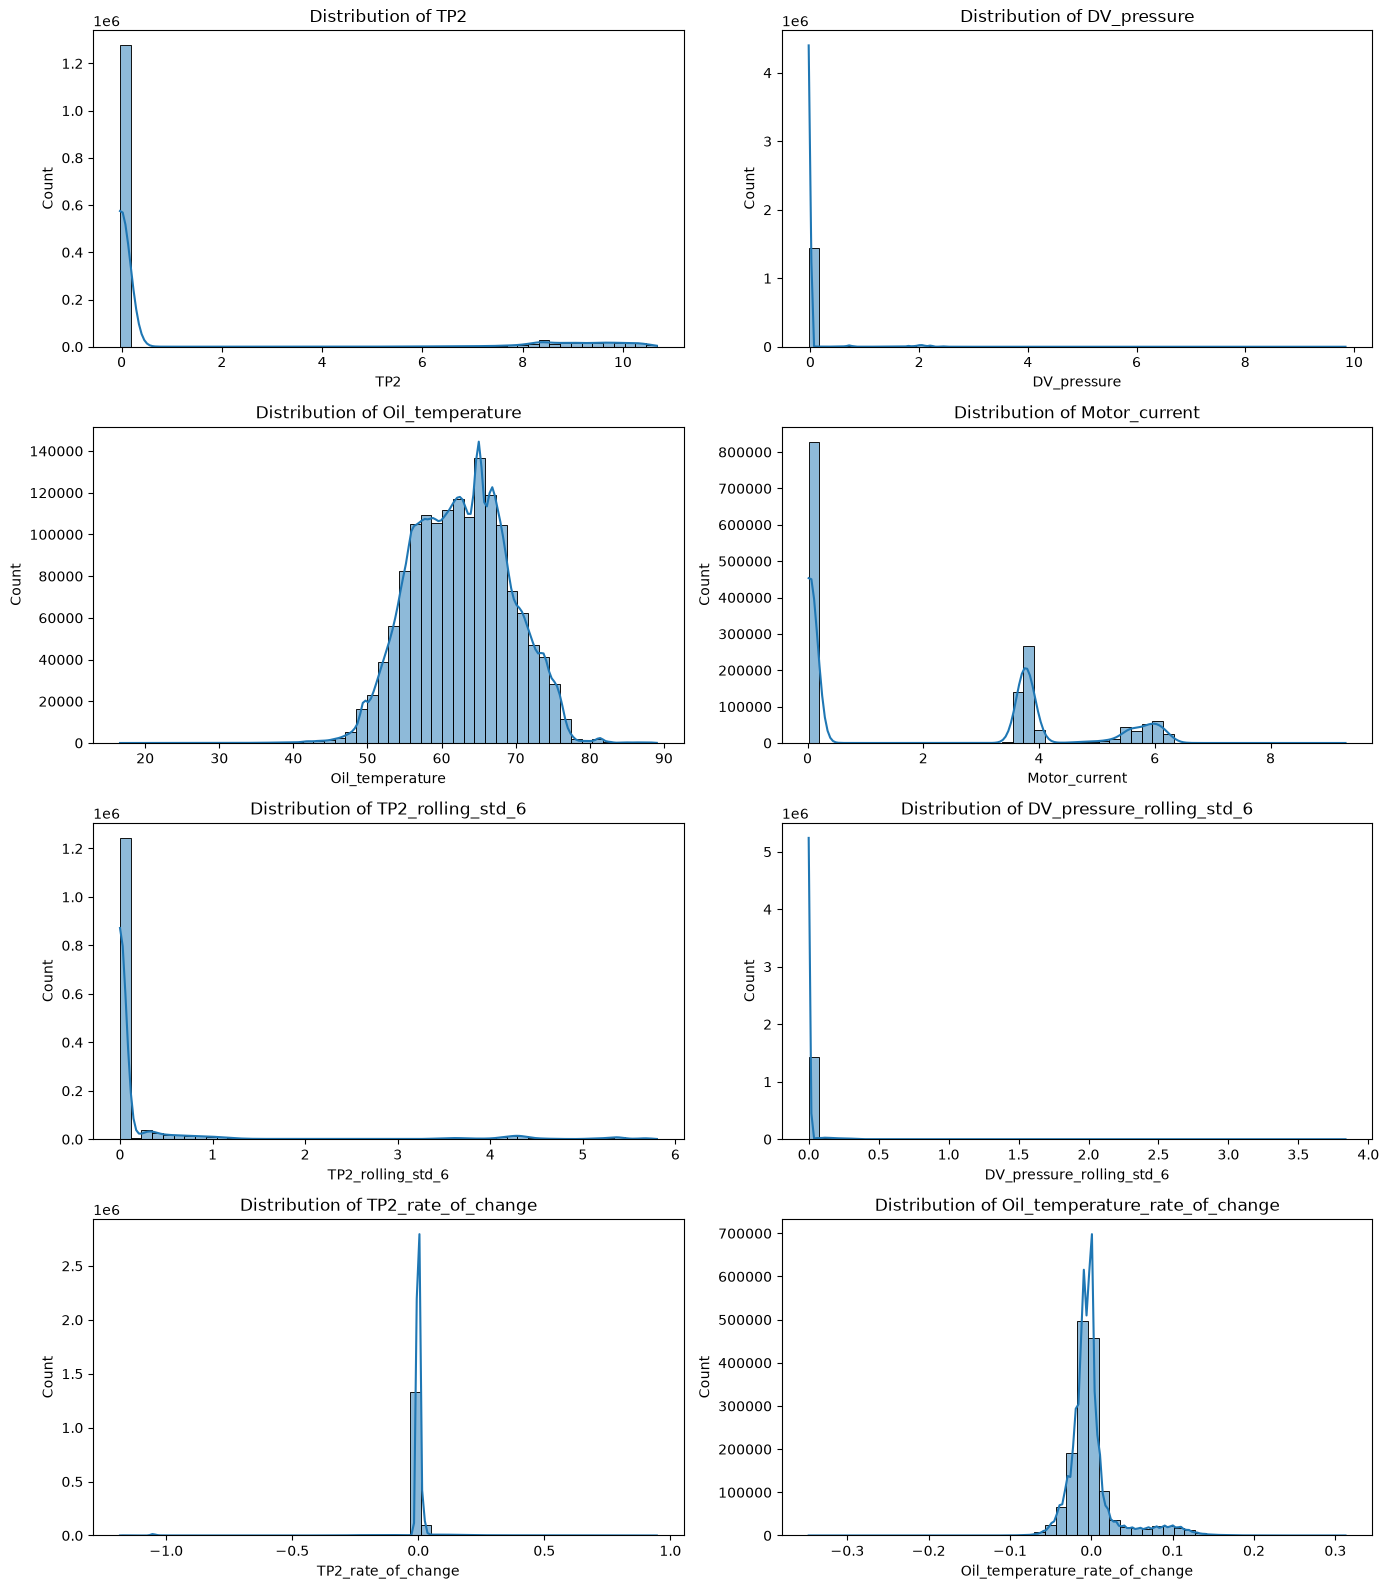

In [85]:
selected_features = [
    'TP2',
    'DV_pressure',
    'Oil_temperature',
    'Motor_current',
    'TP2_rolling_std_6',
    'DV_pressure_rolling_std_6',
    'TP2_rate_of_change',
    'Oil_temperature_rate_of_change'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for col, ax in zip(selected_features, axes.flatten()):
    sns.histplot(
        df_processed[col],
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [86]:
# Final dataset validation

numeric_data = df_processed.select_dtypes(include=np.number)

validation_results = {
    'Dataset Shape': df_processed.shape,
    'Missing Values': df_processed.isnull().sum().sum(),
    'Infinite Values': np.isinf(numeric_data).sum().sum(),
    'Duplicate Rows': df_processed.duplicated().sum(),
    'Chronologically Sorted': df_processed['timestamp'].is_monotonic_increasing,
    'Valid Binary Values': all(
        df_processed[col].isin([0, 1]).all()
        for col in binary_columns
    ),
    'Segment IDs Sorted': df_processed['segment_id'].is_monotonic_increasing
}

for check, result in validation_results.items():
    print(f'{check}: {result}')

Dataset Shape: (1515288, 41)
Missing Values: 0
Infinite Values: 0
Duplicate Rows: 0
Chronologically Sorted: True
Valid Binary Values: True
Segment IDs Sorted: True


In [87]:
df_processed.to_parquet(
    "metropt3_preprocessed.parquet",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
